
# Question 1: Rwanda Maize Yield Dataset Preparation

## Stage 5: Engineer and Select Features

Group: Group 2

Members: Armand Ikirezi and Mariam Nyirarukundo

Target variable: yield_t_ha

Objective: Create meaningful agricultural features, investigate their relationships with maize yield, and select useful features for the next machine-learning stage.

Note: This stage prepares the features. It does not train a prediction model.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split

# Project directory
project_dir = Path(r"D:\MYProject\ML_Element1")

# Load cleaned dataset
cleaned_path = (
    project_dir
    / "q1_maize_yield"
    / "data"
    / "interim"
    / "maize_yield_cleaned.csv"
)

df = pd.read_csv(cleaned_path)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully
Dataset shape: (1426, 20)


,record_id,year,season,province,district,altitude_m,rainfall_mm,avg_temp_c,soil_ph,soil_type,seed_variety,farming_practice,npk_kg_ha,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,irrigation,pest_incidence_index,yield_t_ha
0,RW-MZ-00001,2015,A,Eastern,Bugesera,1349,NaN,22.9,NaN,Clay,RHM104,Improved,117.8,57.4,1.41,61803,0.63,No,NaN,2.71
1,RW-MZ-00002,2015,A,Eastern,Bugesera,1427,489.8,22.1,6.02,Volcanic,RHM104,Improved,38.1,62.7,3.69,52919,0.17,No,0.339,4.09
2,RW-MZ-00003,2015,A,Northern,Burera,2033,722.6,16.3,5.73,Clay loam,Local,Improved,121.1,50.7,5.18,54406,0.22,No,0.049,2.58
3,RW-MZ-00004,2015,A,Northern,Burera,2026,794.4,16.4,5.20,Clay loam,ZM621,Improved,93.7,60.4,1.68,48119,0.48,No,0.171,2.45
4,RW-MZ-00005,2015,A,Northern,Gakenke,1974,644.2,18.3,5.92,Loam,Local,Improved,84.1,70.4,0.36,56787,1.16,No,0.001,2.09


In [2]:

target_column = "yield_t_ha"

# Remove target and record identifier from predictors
X = df.drop(columns=[target_column, "record_id"])
y = df[target_column]

# Reproduce the 70/15/15 split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (998, 18) (998,)
Validation: (214, 18) (214,)
Testing: (214, 18) (214,)


In [3]:

def engineer_features(data):
    data = data.copy()

    # 1. Total mineral fertilizer application
    data["total_mineral_fertilizer_kg_ha"] = (
        data["npk_kg_ha"] + data["urea_kg_ha"]
    )

    # 2. Convert manure from tonnes to kilograms per hectare
    data["manure_kg_ha"] = (
        data["manure_t_ha"] * 1000
    )

    # 3. Estimate total plants on the farm
    data["estimated_total_plants"] = (
        data["plant_density_per_ha"] * data["farm_area_ha"]
    )

    # 4. Rainfall-temperature interaction
    data["rainfall_temperature_interaction"] = (
        data["rainfall_mm"] * data["avg_temp_c"]
    )

    # 5. Distance from neutral soil pH
    data["soil_ph_distance_from_neutral"] = (
        data["soil_ph"] - 7
    ).abs()

    # 6. NPK share of mineral fertilizer
    total_fertilizer = (
        data["npk_kg_ha"] + data["urea_kg_ha"]
    )

    data["npk_fertilizer_share"] = (
        data["npk_kg_ha"] /
        total_fertilizer.replace(0, np.nan)
    )

    return data


# Apply identical feature calculations to all splits
X_train_engineered = engineer_features(X_train)
X_val_engineered = engineer_features(X_val)
X_test_engineered = engineer_features(X_test)

print("Feature engineering completed.")
print("Number of new features:", 6)


Feature engineering completed.
Number of new features: 6


In [4]:

new_features = [
    "total_mineral_fertilizer_kg_ha",
    "manure_kg_ha",
    "estimated_total_plants",
    "rainfall_temperature_interaction",
    "soil_ph_distance_from_neutral",
    "npk_fertilizer_share"
]

display(
    X_train_engineered[new_features].head(10)
)


,total_mineral_fertilizer_kg_ha,manure_kg_ha,estimated_total_plants,rainfall_temperature_interaction,soil_ph_distance_from_neutral,npk_fertilizer_share
390,30.6,1790.0,2936.56,9697.82,1.93,0.000000
573,80.6,780.0,200051.91,13378.48,1.06,0.311414
807,61.3,1820.0,14231.36,7400.88,0.85,0.523654
1228,0.0,3330.0,20253.95,10027.00,1.28,NaN
585,52.1,2360.0,36041.53,10697.68,0.67,0.721689
1384,179.4,890.0,65813.58,8745.10,0.80,0.793200
1356,178.1,1280.0,17129.16,8285.76,1.41,0.666480
308,30.4,1790.0,31086.72,10373.74,0.97,0.000000
680,172.8,2590.0,24535.80,11896.94,1.79,0.594907
578,148.0,790.0,55574.91,11527.11,1.51,0.636486


In [5]:

# Combine engineered training features and target
train_analysis = X_train_engineered.copy()
train_analysis[target_column] = y_train

# Select numerical columns
numeric_train = train_analysis.select_dtypes(
    include=np.number
)

# Calculate correlations with target
correlations = (
    numeric_train.corr()[target_column]
    .drop(target_column)
    .sort_values(ascending=False)
)

display(
    correlations.to_frame(
        name="Correlation with Maize Yield"
    )
)


,Correlation with Maize Yield
rainfall_temperature_interaction,0.393174
rainfall_mm,0.352698
plant_density_per_ha,0.312846
total_mineral_fertilizer_kg_ha,0.264959
urea_kg_ha,0.246600
npk_kg_ha,0.235323
year,0.152653
manure_kg_ha,0.128418
manure_t_ha,0.128418
estimated_total_plants,0.119484


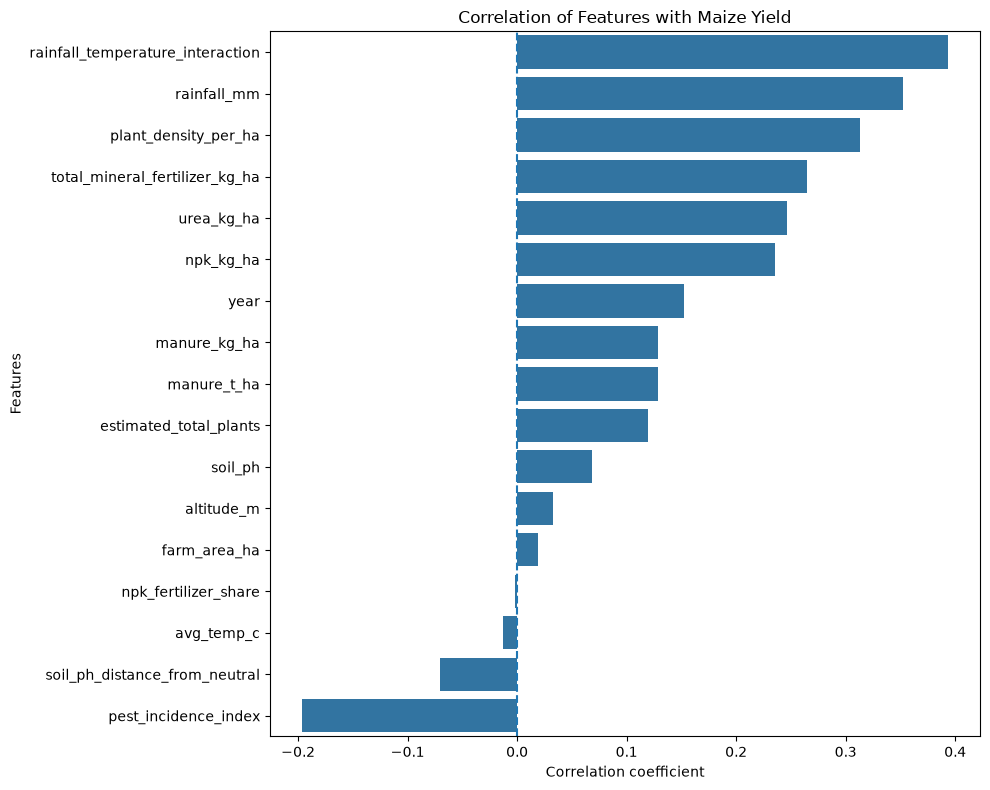

In [6]:

plt.figure(figsize=(10, 8))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.title("Correlation of Features with Maize Yield")
plt.xlabel("Correlation coefficient")
plt.ylabel("Features")
plt.axvline(0, linestyle="--")

plt.tight_layout()
plt.show()


In [7]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_regression

# Identify feature types
numeric_features = X_train_engineered.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train_engineered.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

# Fit on training data only
X_train_prepared = preprocessor.fit_transform(
    X_train_engineered
)

# Transform validation and test data
X_val_prepared = preprocessor.transform(
    X_val_engineered
)

X_test_prepared = preprocessor.transform(
    X_test_engineered
)

prepared_feature_names = preprocessor.get_feature_names_out()

print("Training prepared:", X_train_prepared.shape)
print("Validation prepared:", X_val_prepared.shape)
print("Testing prepared:", X_test_prepared.shape)


Numerical features: ['year', 'altitude_m', 'rainfall_mm', 'avg_temp_c', 'soil_ph', 'npk_kg_ha', 'urea_kg_ha', 'manure_t_ha', 'plant_density_per_ha', 'farm_area_ha', 'pest_incidence_index', 'total_mineral_fertilizer_kg_ha', 'manure_kg_ha', 'estimated_total_plants', 'rainfall_temperature_interaction', 'soil_ph_distance_from_neutral', 'npk_fertilizer_share']
Categorical features: ['season', 'province', 'district', 'soil_type', 'seed_variety', 'farming_practice', 'irrigation']
Training prepared: (998, 70)
Validation prepared: (214, 70)
Testing prepared: (214, 70)


In [8]:

# Select up to 15 features
k_features = min(15, X_train_prepared.shape[1])

selector = SelectKBest(
    score_func=f_regression,
    k=k_features
)

# Fit selector on training data only
X_train_selected = selector.fit_transform(
    X_train_prepared,
    y_train
)

# Apply the same selection to validation and test
X_val_selected = selector.transform(X_val_prepared)
X_test_selected = selector.transform(X_test_prepared)

# Get selected feature names
selected_feature_names = (
    prepared_feature_names[selector.get_support()]
)

print("FINAL SELECTED FEATURES")
print("=======================")

for number, feature in enumerate(
    selected_feature_names,
    start=1
):
    print(f"{number}. {feature}")

print("\nTotal selected features:", len(selected_feature_names))


FINAL SELECTED FEATURES
1. num__rainfall_mm
2. num__npk_kg_ha
3. num__urea_kg_ha
4. num__plant_density_per_ha
5. num__pest_incidence_index
6. num__total_mineral_fertilizer_kg_ha
7. num__rainfall_temperature_interaction
8. cat__season_A
9. cat__season_C
10. cat__soil_type_Volcanic
11. cat__seed_variety_Local
12. cat__seed_variety_PAN691
13. cat__seed_variety_RHM104
14. cat__farming_practice_Improved
15. cat__farming_practice_Traditional

Total selected features: 15


In [9]:

feature_justification = pd.DataFrame([
    {
        "Feature": "total_mineral_fertilizer_kg_ha",
        "Calculation": "npk_kg_ha + urea_kg_ha",
        "Purpose": "Combined mineral fertilizer application rate",
        "Evidence": "Correlation analysis and feature selection"
    },
    {
        "Feature": "manure_kg_ha",
        "Calculation": "manure_t_ha * 1000",
        "Purpose": "Manure application in kilograms per hectare",
        "Evidence": "Correlation analysis and feature selection"
    },
    {
        "Feature": "estimated_total_plants",
        "Calculation": "plant_density_per_ha * farm_area_ha",
        "Purpose": "Estimated total plants on a farm",
        "Evidence": "Correlation analysis and feature selection"
    },
    {
        "Feature": "rainfall_temperature_interaction",
        "Calculation": "rainfall_mm * avg_temp_c",
        "Purpose": "Combined rainfall and temperature measurement",
        "Evidence": "Correlation analysis and feature selection"
    },
    {
        "Feature": "soil_ph_distance_from_neutral",
        "Calculation": "abs(soil_ph - 7)",
        "Purpose": "Distance of soil pH from neutral",
        "Evidence": "Correlation analysis and feature selection"
    },
    {
        "Feature": "npk_fertilizer_share",
        "Calculation": "npk_kg_ha / (npk_kg_ha + urea_kg_ha)",
        "Purpose": "NPK proportion of mineral fertilizer",
        "Evidence": "Correlation analysis and feature selection"
    }
])

display(feature_justification)


,Feature,Calculation,Purpose,Evidence
0,total_mineral_fertilizer_kg_ha,npk_kg_ha + urea_kg_ha,Combined mineral fertilizer application rate,Correlation analysis and feature selection
1,manure_kg_ha,manure_t_ha * 1000,Manure application in kilograms per hectare,Correlation analysis and feature selection
2,estimated_total_plants,plant_density_per_ha * farm_area_ha,Estimated total plants on a farm,Correlation analysis and feature selection
3,rainfall_temperature_interaction,rainfall_mm * avg_temp_c,Combined rainfall and temperature measurement,Correlation analysis and feature selection
4,soil_ph_distance_from_neutral,abs(soil_ph - 7),Distance of soil pH from neutral,Correlation analysis and feature selection
5,npk_fertilizer_share,npk_kg_ha / (npk_kg_ha + urea_kg_ha),NPK proportion of mineral fertilizer,Correlation analysis and feature selection


In [10]:

docs_dir = project_dir / "q1_maize_yield" / "docs"
docs_dir.mkdir(parents=True, exist_ok=True)

feature_justification.to_csv(
    docs_dir / "feature_justification.csv",
    index=False
)

print("Feature Justification table saved.")


Feature Justification table saved.


In [11]:

# Convert selected arrays to DataFrames
X_train_final = pd.DataFrame(
    X_train_selected,
    columns=selected_feature_names,
    index=X_train.index
)

X_val_final = pd.DataFrame(
    X_val_selected,
    columns=selected_feature_names,
    index=X_val.index
)

X_test_final = pd.DataFrame(
    X_test_selected,
    columns=selected_feature_names,
    index=X_test.index
)

# Add target variable to each dataset
train_final = X_train_final.copy()
train_final[target_column] = y_train

validation_final = X_val_final.copy()
validation_final[target_column] = y_val

test_final = X_test_final.copy()
test_final[target_column] = y_test

# Create processed directory
processed_dir = (
    project_dir / "q1_maize_yield" / "data" / "processed"
)
processed_dir.mkdir(parents=True, exist_ok=True)

# Save final datasets
train_final.to_csv(
    processed_dir / "maize_yield_train_final.csv",
    index=False
)

validation_final.to_csv(
    processed_dir / "maize_yield_validation_final.csv",
    index=False
)

test_final.to_csv(
    processed_dir / "maize_yield_test_final.csv",
    index=False
)

print("Final training, validation and test files saved.")


Final training, validation and test files saved.


In [12]:

import joblib

feature_pipeline = {
    "preprocessor": preprocessor,
    "selector": selector,
    "selected_feature_names": selected_feature_names.tolist(),
    "target_column": target_column
}

joblib.dump(
    feature_pipeline,
    processed_dir / "maize_feature_selection_pipeline.joblib"
)

print("Reusable feature pipeline saved.")


Reusable feature pipeline saved.


In [13]:

print("Training shape:", train_final.shape)
print("Validation shape:", validation_final.shape)
print("Testing shape:", test_final.shape)

print(
    "\nSame columns in all datasets:",
    list(train_final.columns)
    == list(validation_final.columns)
    == list(test_final.columns)
)

print("\nMissing values:")
print("Training:", train_final.isnull().sum().sum())
print("Validation:", validation_final.isnull().sum().sum())
print("Testing:", test_final.isnull().sum().sum())


Training shape: (998, 16)
Validation shape: (214, 16)
Testing shape: (214, 16)

Same columns in all datasets: True

Missing values:
Training: 0
Validation: 0
Testing: 0


In [14]:

from pathlib import Path

# Define the main project directory
project_dir = Path(r"D:\MYProject\ML_Element1")

# Define the processed data directory
processed_dir = (
    project_dir
    / "q1_maize_yield"
    / "data"
    / "processed"
)

print("Processed directory:")
print(processed_dir)

print("\nDirectory exists:", processed_dir.exists())


Processed directory:
D:\MYProject\ML_Element1\q1_maize_yield\data\processed

Directory exists: True


In [15]:

print("FILES IN PROCESSED DIRECTORY")

for file in processed_dir.iterdir():
    print(file.name)


FILES IN PROCESSED DIRECTORY
maize_feature_selection_pipeline.joblib
maize_yield_test_final.csv
maize_yield_train_final.csv
maize_yield_validation_final.csv


In [16]:

# Load the saved final datasets
train_path = processed_dir / "maize_yield_train_final.csv"
validation_path = processed_dir / "maize_yield_validation_final.csv"
test_path = processed_dir / "maize_yield_test_final.csv"

train_check = pd.read_csv(train_path)
validation_check = pd.read_csv(validation_path)
test_check = pd.read_csv(test_path)

# Display dataset sizes
print("FINAL DATASET INFORMATION")
print("=========================")

print("\nTRAINING DATASET")
print("Shape:", train_check.shape)
train_check.info()

print("\nVALIDATION DATASET")
print("Shape:", validation_check.shape)
validation_check.info()

print("\nTEST DATASET")
print("Shape:", test_check.shape)
test_check.info()


FINAL DATASET INFORMATION

TRAINING DATASET
Shape: (998, 16)
<class 'pandas.DataFrame'>
RangeIndex: 998 entries, 0 to 997
Data columns (total 16 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   num__rainfall_mm                       998 non-null    float64
 1   num__npk_kg_ha                         998 non-null    float64
 2   num__urea_kg_ha                        998 non-null    float64
 3   num__plant_density_per_ha              998 non-null    float64
 4   num__pest_incidence_index              998 non-null    float64
 5   num__total_mineral_fertilizer_kg_ha    998 non-null    float64
 6   num__rainfall_temperature_interaction  998 non-null    float64
 7   cat__season_A                          998 non-null    float64
 8   cat__season_C                          998 non-null    float64
 9   cat__soil_type_Volcanic                998 non-null    float64
 10  cat__seed_variety_Local 

In [17]:

print("TARGET VARIABLE")
print("================")

print("Target column:", target_column)

print("\nTraining target summary:")
display(train_check[target_column].describe())

print("\nValidation target summary:")
display(validation_check[target_column].describe())

print("\nTest target summary:")
display(test_check[target_column].describe())


TARGET VARIABLE
Target column: yield_t_ha

Training target summary:


count    998.000000
mean       2.560431
std        0.691647
min        1.010000
25%        2.050000
50%        2.550000
75%        3.020000
max        5.010000
Name: yield_t_ha, dtype: float64


Validation target summary:


count    214.000000
mean       2.603879
std        0.709960
min        1.140000
25%        2.052500
50%        2.675000
75%        3.137500
max        4.980000
Name: yield_t_ha, dtype: float64


Test target summary:


count    214.000000
mean       2.630421
std        0.729566
min        1.190000
25%        2.112500
50%        2.600000
75%        3.050000
max        5.150000
Name: yield_t_ha, dtype: float64

In [18]:

print("FINAL VALIDATION")
print("================")

print(
    "Same columns:",
    list(train_check.columns)
    == list(validation_check.columns)
    == list(test_check.columns)
)

print("Training missing values:",
      train_check.isnull().sum().sum())

print("Validation missing values:",
      validation_check.isnull().sum().sum())

print("Test missing values:",
      test_check.isnull().sum().sum())

print("Target included:",
      target_column in train_check.columns)


FINAL VALIDATION
Same columns: True
Training missing values: 0
Validation missing values: 0
Test missing values: 0
Target included: True
